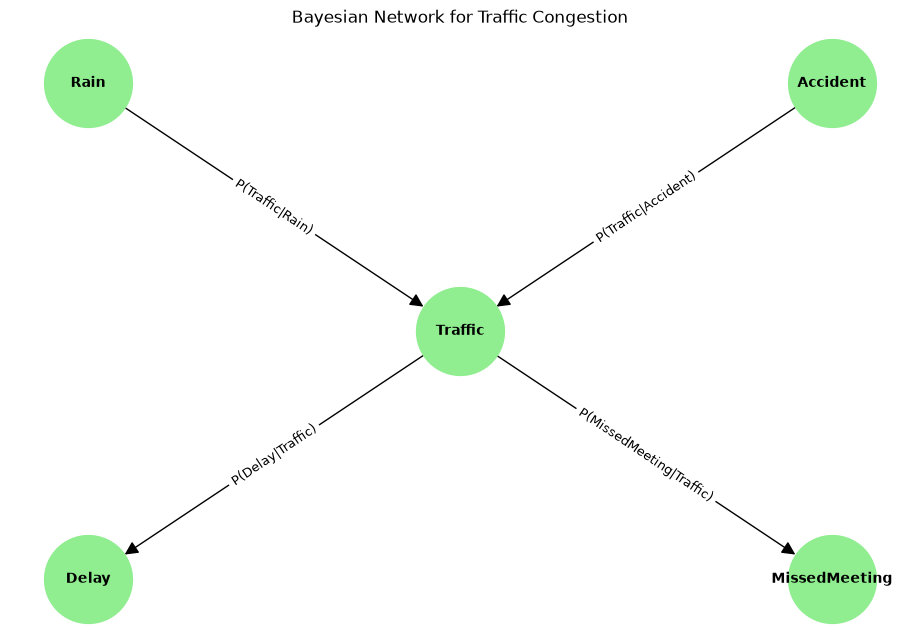

Is the Bayesian Network Valid? True

CPD of Rain:
 +---------+-----+
| Rain(0) | 0.7 |
+---------+-----+
| Rain(1) | 0.3 |
+---------+-----+

CPD of Accident:
 +-------------+------+
| Accident(0) | 0.95 |
+-------------+------+
| Accident(1) | 0.05 |
+-------------+------+

CPD of Traffic:
 +------------+-------------+-------------+-------------+-------------+
| Rain       | Rain(0)     | Rain(0)     | Rain(1)     | Rain(1)     |
+------------+-------------+-------------+-------------+-------------+
| Accident   | Accident(0) | Accident(1) | Accident(0) | Accident(1) |
+------------+-------------+-------------+-------------+-------------+
| Traffic(0) | 0.1         | 0.3         | 0.4         | 0.9         |
+------------+-------------+-------------+-------------+-------------+
| Traffic(1) | 0.9         | 0.7         | 0.6         | 0.1         |
+------------+-------------+-------------+-------------+-------------+

CPD of Delay:
 +----------+------------+------------+
| Traffic  | 

In [ ]:

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import matplotlib.pyplot as plt

nodes = ["Rain", "Accident", "Traffic", "Delay", "MissedMeeting"]
edges = [("Rain", "Traffic"), ("Accident", "Traffic"),
         ("Traffic", "Delay"), ("Traffic", "MissedMeeting")]

graph = nx.DiGraph()
graph.add_nodes_from(nodes)
graph.add_edges_from(edges)

pos = {"Rain": (0, 2), "Accident": (2, 2), "Traffic": (1, 1),
       "Delay": (0, 0), "MissedMeeting": (2, 0)}

network = DiscreteBayesianNetwork(edges)

plt.figure(figsize=(9, 6))
nx.draw(graph, pos, with_labels=True, node_size=4000,
        node_color="lightgreen", font_size=10,
        font_weight="bold", arrowsize=20)

edge_labels = {
    ("Rain", "Traffic"): "P(Traffic|Rain)",
    ("Accident", "Traffic"): "P(Traffic|Accident)",
    ("Traffic", "Delay"): "P(Delay|Traffic)",
    ("Traffic", "MissedMeeting"): "P(MissedMeeting|Traffic)"
}
nx.draw_networkx_edge_labels(graph, pos, edge_labels=edge_labels, font_size=9)
plt.title("Bayesian Network for Traffic Congestion")
plt.show()


cpd_rain = TabularCPD("Rain", 2, [[0.70], [0.30]])
cpd_accident = TabularCPD("Accident", 2, [[0.95], [0.05]])

cpd_traffic = TabularCPD(
    "Traffic", 2,
    [[0.10, 0.30, 0.40, 0.90],
     [0.90, 0.70, 0.60, 0.10]],
    evidence=["Rain", "Accident"], evidence_card=[2, 2])

cpd_delay = TabularCPD(
    "Delay", 2, [[0.20, 0.80], [0.80, 0.20]],
    evidence=["Traffic"], evidence_card=[2])

cpd_missed_meeting = TabularCPD(
    "MissedMeeting", 2, [[0.50, 0.95], [0.50, 0.05]],
    evidence=["Traffic"], evidence_card=[2])

network.add_cpds(cpd_rain, cpd_accident, cpd_traffic,
                 cpd_delay, cpd_missed_meeting)

print("Is the Bayesian Network Valid?", network.check_model())
print("\nCPD of Rain:\n", cpd_rain)
print("\nCPD of Accident:\n", cpd_accident)
print("\nCPD of Traffic:\n", cpd_traffic)
print("\nCPD of Delay:\n", cpd_delay)
print("\nCPD of MissedMeeting:\n", cpd_missed_meeting)


# Code for variable enumeration

class BayesNode:
    def __init__(self, name, parents, cpt):
        self.name = name
        self.parents = parents
        self.cpt = cpt

    def p(self, value, event):
        key = tuple(event[parent] for parent in self.parents)
        prob = self.cpt[key]
        return prob if value else 1 - prob


class BayesNet:
    def __init__(self, nodes):
        self.nodes = nodes
        self.variables = [node.name for node in nodes]

    def variable_node(self, var):
        for node in self.nodes:
            if node.name == var:
                return node

    def variable_values(self, var):
        return [True, False]


def enumerate_all(variables, e, bn):
    if not variables:
        return 1.0

    Y = variables[0]
    node = bn.variable_node(Y)

    if Y in e:
        return node.p(e[Y], e) * enumerate_all(variables[1:], e, bn)
    else:
        total = 0
        for y in [True, False]:
            ex = e.copy()
            ex[Y] = y
            total += node.p(y, ex) * enumerate_all(variables[1:], ex, bn)
        return total


def Normalize(Q):
    total = sum(Q.values())
    return {key: value / total for key, value in Q.items()}


def enumeration_ask(X, e, bn):
    Q = {}
    for x in [True, False]:
        ex = e.copy()
        ex[X] = x
        Q[x] = enumerate_all(bn.variables, ex, bn)
    return Normalize(Q)
   

R = BayesNode("R", [], {(): 0.30})
A = BayesNode("A", [], {(): 0.05})

T = BayesNode("T", ["R", "A"], {
    (True, True): 0.90,
    (True, False): 0.70,
    (False, True): 0.60,
    (False, False): 0.10
})

D = BayesNode("D", ["T"], {
    (True,): 0.80,
    (False,): 0.20
})

M = BayesNode("M", ["T"], {
    (True,): 0.50,
    (False,): 0.05
})

bn = BayesNet([R, A, T, D, M])

result = enumeration_ask("R", {"D": True, "M": True}, bn)

print("\nP(R | D=True, M=True)")
print("R = True:", round(result[True], 4))
print("R = False:", round(result[False], 4))


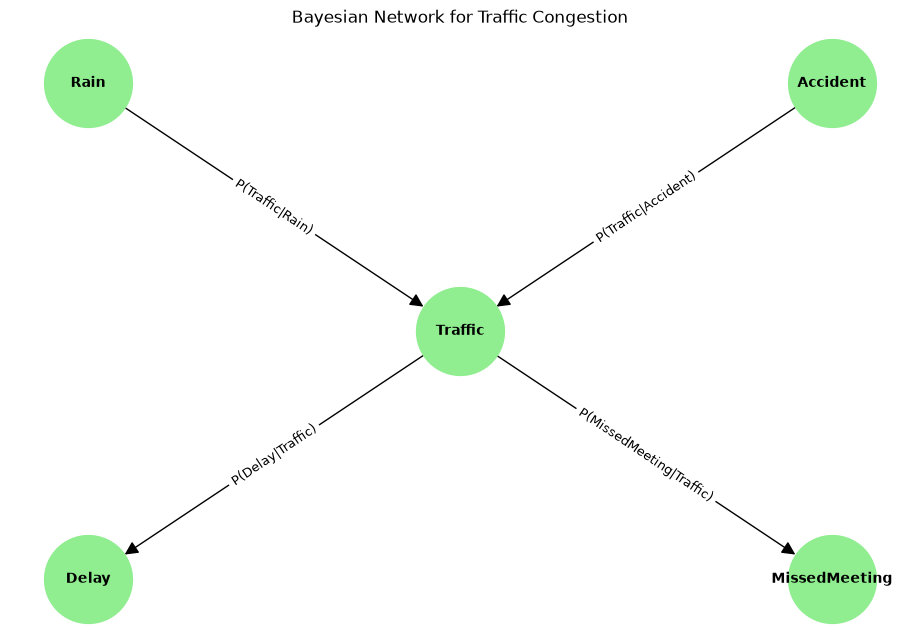

Is the Bayesian Network Valid? True

CPD of Rain:
 +---------+-----+
| Rain(0) | 0.7 |
+---------+-----+
| Rain(1) | 0.3 |
+---------+-----+

CPD of Accident:
 +-------------+------+
| Accident(0) | 0.95 |
+-------------+------+
| Accident(1) | 0.05 |
+-------------+------+

CPD of Traffic:
 +------------+-------------+-------------+-------------+-------------+
| Rain       | Rain(0)     | Rain(0)     | Rain(1)     | Rain(1)     |
+------------+-------------+-------------+-------------+-------------+
| Accident   | Accident(0) | Accident(1) | Accident(0) | Accident(1) |
+------------+-------------+-------------+-------------+-------------+
| Traffic(0) | 0.1         | 0.3         | 0.4         | 0.9         |
+------------+-------------+-------------+-------------+-------------+
| Traffic(1) | 0.9         | 0.7         | 0.6         | 0.1         |
+------------+-------------+-------------+-------------+-------------+

CPD of Delay:
 +----------+------------+------------+
| Traffic  | 

In [10]:

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import matplotlib.pyplot as plt

nodes = ["Rain", "Accident", "Traffic", "Delay", "MissedMeeting"]
edges = [("Rain", "Traffic"), ("Accident", "Traffic"),
         ("Traffic", "Delay"), ("Traffic", "MissedMeeting")]

graph = nx.DiGraph()
graph.add_nodes_from(nodes)
graph.add_edges_from(edges)

pos = {"Rain": (0, 2), "Accident": (2, 2), "Traffic": (1, 1),
       "Delay": (0, 0), "MissedMeeting": (2, 0)}

network = DiscreteBayesianNetwork(edges)

plt.figure(figsize=(9, 6))
nx.draw(graph, pos, with_labels=True, node_size=4000,
        node_color="lightgreen", font_size=10,
        font_weight="bold", arrowsize=20)

edge_labels = {
    ("Rain", "Traffic"): "P(Traffic|Rain)",
    ("Accident", "Traffic"): "P(Traffic|Accident)",
    ("Traffic", "Delay"): "P(Delay|Traffic)",
    ("Traffic", "MissedMeeting"): "P(MissedMeeting|Traffic)"
}
nx.draw_networkx_edge_labels(graph, pos, edge_labels=edge_labels, font_size=9)
plt.title("Bayesian Network for Traffic Congestion")
plt.show()


cpd_rain = TabularCPD("Rain", 2, [[0.70], [0.30]])
cpd_accident = TabularCPD("Accident", 2, [[0.95], [0.05]])

cpd_traffic = TabularCPD(
    "Traffic", 2,
    [[0.10, 0.30, 0.40, 0.90],
     [0.90, 0.70, 0.60, 0.10]],
    evidence=["Rain", "Accident"], evidence_card=[2, 2])

cpd_delay = TabularCPD(
    "Delay", 2, [[0.20, 0.80], [0.80, 0.20]],
    evidence=["Traffic"], evidence_card=[2])

cpd_missed_meeting = TabularCPD(
    "MissedMeeting", 2, [[0.50, 0.95], [0.50, 0.05]],
    evidence=["Traffic"], evidence_card=[2])

network.add_cpds(cpd_rain, cpd_accident, cpd_traffic,
                 cpd_delay, cpd_missed_meeting)

print("Is the Bayesian Network Valid?", network.check_model())
print("\nCPD of Rain:\n", cpd_rain)
print("\nCPD of Accident:\n", cpd_accident)
print("\nCPD of Traffic:\n", cpd_traffic)
print("\nCPD of Delay:\n", cpd_delay)
print("\nCPD of MissedMeeting:\n", cpd_missed_meeting)

# Probabilities
P_R = 0.30
P_A = 0.05

P_T = {
    (True, True): 0.90,
    (True, False): 0.70,
    (False, True): 0.60,
    (False, False): 0.10
}

P_D = {True: 0.80, False: 0.20}
P_M = {True: 0.50, False: 0.05}


# Calculate joint probability
def enumerate_all(r, a, t, d, m):

    pr = P_R if r else 1 - P_R

    pa = P_A if a else 1 - P_A

    pt = P_T[(r, a)] if t else 1 - P_T[(r, a)]

    pd = P_D[t] if d else 1 - P_D[t]

    pm = P_M[t] if m else 1 - P_M[t]

    return pr * pa * pt * pd * pm


# Enumeration
true_sum = 0
false_sum = 0

for a in [True, False]:
    for t in [True, False]:

        true_sum += enumerate_all(True, a, t, True, True)

        false_sum += enumerate_all(False, a, t, True, True)


# Normalize
result1 = true_sum / (true_sum + false_sum)
result2 = false_sum / (true_sum + false_sum)


print("P(Rain-True | Delay, MissedMeeting) =", result1)
print("P(Rain-False | Delay, MissedMeeting) =", result2)

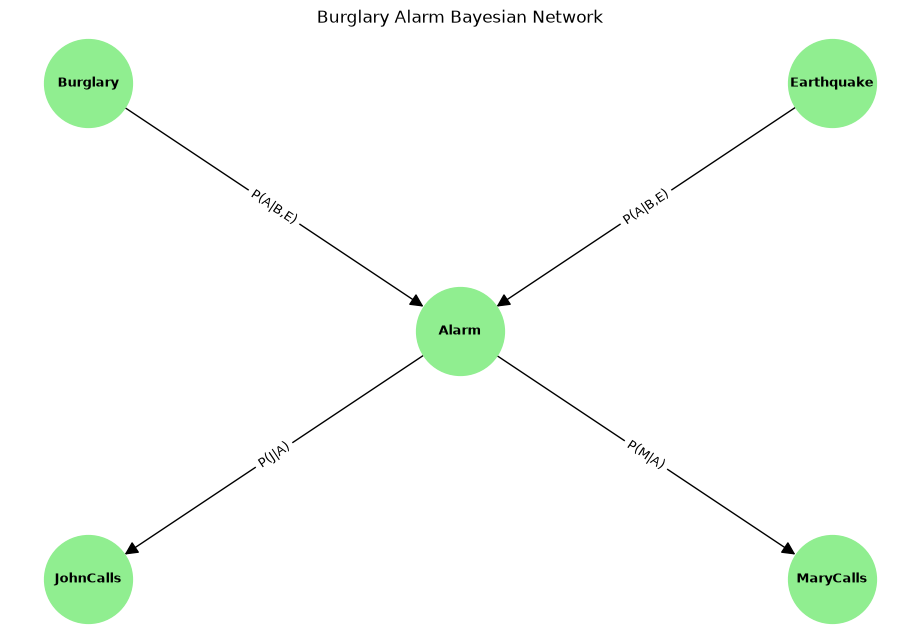

Network valid: True

CPD Burglary:
 +-------------+-------+
| Burglary(0) | 0.999 |
+-------------+-------+
| Burglary(1) | 0.001 |
+-------------+-------+

CPD Earthquake:
 +---------------+-------+
| Earthquake(0) | 0.998 |
+---------------+-------+
| Earthquake(1) | 0.002 |
+---------------+-------+

CPD Alarm:
 +------------+---------------+---------------+---------------+---------------+
| Burglary   | Burglary(0)   | Burglary(0)   | Burglary(1)   | Burglary(1)   |
+------------+---------------+---------------+---------------+---------------+
| Earthquake | Earthquake(0) | Earthquake(1) | Earthquake(0) | Earthquake(1) |
+------------+---------------+---------------+---------------+---------------+
| Alarm(0)   | 0.999         | 0.71          | 0.06          | 0.05          |
+------------+---------------+---------------+---------------+---------------+
| Alarm(1)   | 0.001         | 0.29          | 0.94          | 0.95          |
+------------+---------------+---------------+-----

In [ ]:

# %pip install pgmpy networkx matplotlib

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import matplotlib.pyplot as plt
nodes = ["Burglary", "Earthquake", "Alarm",
         "JohnCalls", "MaryCalls"]

edges = [
    ("Burglary", "Alarm"),
    ("Earthquake", "Alarm"),
    ("Alarm", "JohnCalls"),
    ("Alarm", "MaryCalls")
]


network = DiscreteBayesianNetwork(edges)
graph = nx.DiGraph()
graph.add_nodes_from(nodes)
graph.add_edges_from(edges)

pos = {
    "Burglary": (0, 2),
    "Earthquake": (2, 2),
    "Alarm": (1, 1),
    "JohnCalls": (0, 0),
    "MaryCalls": (2, 0)
}

plt.figure(figsize=(9, 6))

nx.draw(
    graph, pos,
    with_labels=True,
    node_size=4000,
    node_color="lightgreen",
    font_size=9,
    font_weight="bold",
    arrowsize=20
)

# 5. Edge Labels
edge_labels = {
    ("Burglary", "Alarm"): "P(A|B,E)",
    ("Earthquake", "Alarm"): "P(A|B,E)",
    ("Alarm", "JohnCalls"): "P(J|A)",
    ("Alarm", "MaryCalls"): "P(M|A)"
}

nx.draw_networkx_edge_labels(
    graph, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Burglary Alarm Bayesian Network")
plt.show()

# 6. CPDs

cpd_b = TabularCPD(
    "Burglary", 2,
    [[0.999], [0.001]]
)

cpd_e = TabularCPD(
    "Earthquake", 2,
    [[0.998], [0.002]]
)

cpd_a = TabularCPD(
    "Alarm", 2,
    [
        [0.999, 0.71, 0.06, 0.05],
        [0.001, 0.29, 0.94, 0.95]
    ],
    evidence=["Burglary", "Earthquake"],
    evidence_card=[2, 2]
)

cpd_j = TabularCPD(
    "JohnCalls", 2,
    [[0.95, 0.10],
     [0.05, 0.90]],
    evidence=["Alarm"],
    evidence_card=[2]
)

cpd_m = TabularCPD(
    "MaryCalls", 2,
    [[0.99, 0.30],
     [0.01, 0.70]],
    evidence=["Alarm"],
    evidence_card=[2]
)

network.add_cpds(cpd_b, cpd_e, cpd_a, cpd_j, cpd_m)

print("Network valid:", network.check_model())

print("\nCPD Burglary:\n", cpd_b)
print("\nCPD Earthquake:\n", cpd_e)
print("\nCPD Alarm:\n", cpd_a)
print("\nCPD JohnCalls:\n", cpd_j)
print("\nCPD MaryCalls:\n", cpd_m)


p_b = cpd_b.values[1]
p_e = cpd_e.values[0]
p_a = cpd_a.values[1, 1, 0]
p_j = cpd_j.values[1, 1]
p_m = cpd_m.values[1, 1]

joint_probability = (
    p_b * p_e * p_a * p_j * p_m
)

print("\nJoint Probability:")
print("P(B,E=False,A,J,M) =", joint_probability)


#ENUMERATION

P_B = 0.001
P_E = 0.002

P_A = {
    (True, True): 0.95,
    (True, False): 0.94,
    (False, True): 0.29,
    (False, False): 0.001
}

P_J = {True: 0.90, False: 0.05}
P_M = {True: 0.70, False: 0.01}

def enumerate_all(b,e,a,j,m):
    pb=P_B if b else 1-P_B
    pe=P_E if e else 1-P_E
    pa=P_A[(b,e)] if a else 1-P_A[(b,e)]
    pj=P_J[a] if j else 1-P_J
    pm=P_M[a] if j else 1-P_M
    return pb*pe*pa*pj*pm
true_sum=0
false_sum=0
for a in (True,False):
    for e in (True,False):
        true_sum+=enumerate_all(True,e,a,True,True)
        false_sum+=enumerate_all(False,e,a,True,True)
result=true_sum/(true_sum+false_sum)
print("P(B|J,M)=",result)
        

    
